<a href="https://colab.research.google.com/github/cwilson-su/Large-Scale-Data-Analytics-Labs/blob/main/LAB4_LSDA_2026_json_management.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

* LSDA, Master MIND, Sorbonne University
* Mohamed-Amine Baazizi, Sorbonne University, mohamed-amine.baazizi@sorbonne-universite.fr
* Date: October 2026


# Managing semi-structured data  

## Identification (à remplir)
- Nom : ...
- Matricule : ...



## Description

The data describes Github metadata in JSON format.
First, design a database model, using views, by focusing on the data that is meaningful for answering the above analytical questions.
The views are built using transformation queries that pre-process the data and remove duplicates, when necessary.
- https://www.gharchive.org


The goal is to formulate anlaytical queries answering the following questions.

**Analytical questions**


- Q1 — Hourly activity by event type
- Q2 — Top 10 repos by distinct pushers
- Q3 — Share of bot activity per event type. To check for bot activity, use pattern matching on login (e.g. `LIKE '%[bot]'`)
- Q4 — Top 3 human actors per event type
- Q5 — Time to first reply on issues opened that day
- Q6 — Most used labels and the share of their issues already closed
- Q7 — Stars, forks and PRs per repo. Use WatchEvent and ForkEvent

**Methodology**

First explore the complex structure of the raw data. Then suggest a normalized schema by creating tables with data relevant to answering the questions (you could refer to the appendix for a suggested data model).

- https://docs.databricks.com/aws/en/semi-structured



## Preparation

### Spark set up

In [ ]:
%%capture
!pip install pyspark==4.1.0
!pip install -q delta-spark==4.3.0

In [ ]:
from pyspark import SparkConf
from pyspark.context import SparkContext
from pyspark.sql import SparkSession

local = "local[*]"
appName = "MIND, LSDA"
localConfig = SparkConf().setAppName(appName).setMaster(local).\
  set("spark.executor.memory", "8G").\
  set("spark.driver.memory","8G").\
  set("spark.sql.catalogImplementation","in-memory").\
  set("spark.sql.extensions","io.delta.sql.DeltaSparkSessionExtension").\
  set("spark.sql.catalog.spark_catalog","org.apache.spark.sql.delta.catalog.DeltaCatalog").\
  set("spark.jars.packages","io.delta:delta-spark_2.13:4.3.0").\
  set("spark.databricks.delta.schema.autoMerge.enabled","true")

spark = SparkSession.builder.config(conf = localConfig).getOrCreate()
sc = spark.sparkContext
sc.setLogLevel("ERROR")

In [ ]:
spark

### Data downloading

In [ ]:
! mkdir -p /content/lsda/gh

In [ ]:
! wget  https://data.gharchive.org/2015-01-01-15.json.gz -O /tmp/2015-01-01-15.json.gz


--2026-10-15 13:49:48--  https://data.gharchive.org/2015-01-01-15.json.gz
Resolving data.gharchive.org (data.gharchive.org)... 172.67.168.206, 104.21.46.175, 2606:4700:3033::ac43:a8ce, ...
Connecting to data.gharchive.org (data.gharchive.org)|172.67.168.206|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3844072 (3.7M) [application/gzip]
Saving to: ‘/tmp/2015-01-01-15.json.gz’

/tmp/2015-01-01-15. 100%[===================>]   3.67M  --.-KB/s    in 0.06s   

2026-10-15 13:49:48 (59.9 MB/s) - ‘/tmp/2015-01-01-15.json.gz’ saved [3844072/3844072]



In [ ]:
! ls -hal /tmp/2015-01-01-15.json.gz

-rw-r--r-- 1 root root 3.7M Apr  2  2018 /tmp/2015-01-01-15.json.gz


In [ ]:
# gunzip /tmp/2015-01-01-15.json.gz -d /content/lsda/gh

## Demo
This part illustrates the use variant types in Apache Spark

### flat data

In [ ]:
query = """
CREATE OR REPLACE TEMP VIEW json_data AS
SELECT '{"name": "Alice", "age": 25}' AS v UNION ALL
SELECT '{"name": "Bob", "age": 30}' UNION ALL
SELECT '{"id": 101, "department": "HR"}' UNION ALL
SELECT '{"product": "Laptop", "price": 1200.50, "in_stock": true}';
"""
spark.sql(query).show(truncate=False)

++
||
++
++



-- Return the schema


In [ ]:
query = """
SELECT schema_of_variant(parse_json(v)) FROM json_data;
"""
spark.sql(query).show(truncate=False)

+---------------------------------------------------------------+
|schema_of_variant(parse_json(v))                               |
+---------------------------------------------------------------+
|OBJECT<age: BIGINT, name: STRING>                              |
|OBJECT<age: BIGINT, name: STRING>                              |
|OBJECT<department: STRING, id: BIGINT>                         |
|OBJECT<in_stock: BOOLEAN, price: DECIMAL(5,1), product: STRING>|
+---------------------------------------------------------------+



In [ ]:
query = """
SELECT parse_json(v) FROM json_data;
"""
spark.sql(query).show(truncate=False)

+---------------------------------------------------+
|parse_json(v)                                      |
+---------------------------------------------------+
|{"age":25,"name":"Alice"}                          |
|{"age":30,"name":"Bob"}                            |
|{"department":"HR","id":101}                       |
|{"in_stock":true,"price":1200.5,"product":"Laptop"}|
+---------------------------------------------------+



In [ ]:
query = """
SELECT schema_of_variant_agg(parse_json(v)) FROM json_data;
"""
spark.sql(query).show(truncate=False)

+--------------------------------------------------------------------------------------------------------------------------+
|schema_of_variant_agg(parse_json(v))                                                                                      |
+--------------------------------------------------------------------------------------------------------------------------+
|OBJECT<age: BIGINT, department: STRING, id: BIGINT, in_stock: BOOLEAN, name: STRING, price: DECIMAL(5,1), product: STRING>|
+--------------------------------------------------------------------------------------------------------------------------+



### nested data

In [ ]:
query = """
CREATE OR REPLACE TEMP VIEW src AS
SELECT 1 AS id,
        parse_json
        ('[
          {
            "author":"Nigel Rees",
            "title":"Sayings of the Century",
            "category":"reference",
            "price":8.95
          },
          {
            "author":"Herman Melville",
            "title":"Moby Dick",
            "category":"fiction",
            "price":8.99,
            "isbn":"0-553-21311-3"
          },
          {
            "author":"J. R. R. Tolkien",
            "title":"The Lord of the Rings",
            "category":"fiction",
            "reader":[
              {"age":25,"name":"bob"},
              {"age":26,"name":"jack"}
            ],
            "price":22.99,
            "isbn":"0-395-19395-8"
          }
        ]') as jvalue
"""
spark.sql(query).show()

++
||
++
++



In [ ]:
query = """
SELECT jvalue FROM src;
"""
spark.sql(query).show(truncate=False)

+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|jvalue                                                                                                                                                                                                                                                                                                                                                                                      |
+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [ ]:
query = """
CREATE OR REPLACE TEMP VIEW books AS
SELECT s.id, e.pos, e.value AS obj
FROM src s,
     LATERAL variant_explode(s.jvalue) AS e;
     """
spark.sql(query).show(truncate=False)

++
||
++
++



In [ ]:
query = """
SELECT * FROM books;
"""
spark.sql(query).show(truncate=False)

+---+---+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|id |pos|obj                                                                                                                                                                                |
+---+---+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|1  |0  |{"author":"Nigel Rees","category":"reference","price":8.95,"title":"Sayings of the Century"}                                                                                       |
|1  |1  |{"author":"Herman Melville","category":"fiction","isbn":"0-553-21311-3","price":8.99,"title":"Moby Dick"}                                                                          |
|1  |2  |{"author":"J. R. R. Tolkien","category":"

In [ ]:
query = """
describe books
"""
spark.sql(query).show()

+--------+---------+-------+
|col_name|data_type|comment|
+--------+---------+-------+
|      id|      int|   NULL|
|     pos|      int|   NULL|
|     obj|  variant|   NULL|
+--------+---------+-------+



-- Return the schema of the variant


In [ ]:
query = """
SELECT schema_of_variant(obj) FROM books;
"""
spark.sql(query).show(truncate=False)



+--------------------------------------------------------------------------------------------------------------------------------------------+
|schema_of_variant(obj)                                                                                                                      |
+--------------------------------------------------------------------------------------------------------------------------------------------+
|OBJECT<author: STRING, category: STRING, price: DECIMAL(3,2), title: STRING>                                                                |
|OBJECT<author: STRING, category: STRING, isbn: STRING, price: DECIMAL(3,2), title: STRING>                                                  |
|OBJECT<author: STRING, category: STRING, isbn: STRING, price: DECIMAL(4,2), reader: ARRAY<OBJECT<age: BIGINT, name: STRING>>, title: STRING>|
+--------------------------------------------------------------------------------------------------------------------------------------------+

In [ ]:
query = """
SELECT schema_of_variant_agg(obj) FROM books;
"""
spark.sql(query).show(truncate=False)

+--------------------------------------------------------------------------------------------------------------------------------------------+
|schema_of_variant_agg(obj)                                                                                                                  |
+--------------------------------------------------------------------------------------------------------------------------------------------+
|OBJECT<author: STRING, category: STRING, isbn: STRING, price: DECIMAL(4,2), reader: ARRAY<OBJECT<age: BIGINT, name: STRING>>, title: STRING>|
+--------------------------------------------------------------------------------------------------------------------------------------------+



-- Extract a top-level field


In [ ]:
query = """
SELECT obj:reader FROM books
"""
spark.sql(query).show(truncate=False)

+--------------------------------------------------+
|reader                                            |
+--------------------------------------------------+
|NULL                                              |
|NULL                                              |
|[{"age":25,"name":"bob"},{"age":26,"name":"jack"}]|
+--------------------------------------------------+



In [ ]:
query = """
SELECT variant_get(obj, '$.reader') FROM books
"""
spark.sql(query).show(truncate=False)

+--------------------------------------------------+
|variant_get(obj, $.reader)                        |
+--------------------------------------------------+
|NULL                                              |
|NULL                                              |
|[{"age":25,"name":"bob"},{"age":26,"name":"jack"}]|
+--------------------------------------------------+



In [ ]:
query = """
SELECT obj:reader[0] as r1,obj:reader[1] as r2 FROM books
where obj:reader is not null
"""
spark.sql(query).show(truncate=False)

+-----------------------+------------------------+
|r1                     |r2                      |
+-----------------------+------------------------+
|{"age":25,"name":"bob"}|{"age":26,"name":"jack"}|
+-----------------------+------------------------+



In [ ]:
query = """
SELECT obj:reader FROM books
where is_variant_null(obj:reader) = false
"""
spark.sql(query).show(truncate=False)

+--------------------------------------------------+
|reader                                            |
+--------------------------------------------------+
|NULL                                              |
|NULL                                              |
|[{"age":25,"name":"bob"},{"age":26,"name":"jack"}]|
+--------------------------------------------------+



In [ ]:
query = """
"""
spark.sql(query).show(truncate=False)

## Use-case to solve


#### Dataset loading

In [ ]:
query = """
CREATE TABLE IF NOT EXISTS all_objects
USING json
OPTIONS (
  path "/content/lsda/gh/2015-01-01-15.json"
)
"""
spark.sql(query)

DataFrame[]

In [ ]:
from pyspark.sql import functions as F
SRC = "/tmp/2015-01-01-15.json.gz"

test

In [ ]:
query = """
CREATE OR REPLACE TEMP VIEW raw_v AS
SELECT parse_json(value) AS e FROM text.`/tmp/2015-01-01-15.json.gz`;
"""
spark.sql(query)





DataFrame[]

In [ ]:
query = """
describe raw_v
"""
spark.sql(query).show()


+--------+---------+-------+
|col_name|data_type|comment|
+--------+---------+-------+
|       e|  variant|   NULL|
+--------+---------+-------+



In [ ]:
query = """
SELECT variant_get(e, '$.type', 'string')            AS type,
       count(*)                                        AS n,
       schema_of_variant_agg(variant_get(e, '$.payload', 'variant')) AS payload_schema
FROM raw_v GROUP BY 1 ORDER BY n DESC;
"""
spark.sql(query).show(truncate=False)

+-----------------------------+----+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

#### How many objects in the reviews collection

In [ ]:
query = """
select count(*) as count from all_objects
"""
spark.sql(query).show()

+-----+
|count|
+-----+
|11351|
+-----+



#### object count per event type

In [ ]:
query = """
select type, count(*) as nb_objects from all_objects group by type order by nb_objects desc
"""
spark.sql(query).show()

+--------------------+----------+
|                type|nb_objects|
+--------------------+----------+
|           PushEvent|      5815|
|         CreateEvent|      1471|
|          WatchEvent|      1230|
|   IssueCommentEvent|       844|
|         IssuesEvent|       545|
|    PullRequestEvent|       474|
|           ForkEvent|       355|
|         DeleteEvent|       260|
|PullRequestReview...|       136|
|  CommitCommentEvent|        73|
|         GollumEvent|        61|
|        ReleaseEvent|        60|
|         MemberEvent|        25|
|         PublicEvent|         2|
+--------------------+----------+



#### normalized schema
below are some examples of how to create flat tables. You can use them or propose tables of your own.

##### actors

In [ ]:
query = """
drop table if exists actors
"""
spark.sql(query).show()

++
||
++
++



In [ ]:
query = """
CREATE TABLE actors as select distinct actor.*
from all_objects
"""
spark.sql(query).show()

++
||
++
++



In [ ]:
query = """
select count(*)
from actors
"""
spark.sql(query).show()

+--------+
|count(1)|
+--------+
|    5250|
+--------+



In [ ]:
query = """
select *
from actors
"""
spark.sql(query).show(truncate=False)

+-------------------------------------------------+-----------+--------+-------------------+------------------------------------------------+
|avatar_url                                       |gravatar_id|id      |login              |url                                             |
+-------------------------------------------------+-----------+--------+-------------------+------------------------------------------------+
|https://avatars.githubusercontent.com/u/1450716? |           |1450716 |luigino            |https://api.github.com/users/luigino            |
|https://avatars.githubusercontent.com/u/785706?  |           |785706  |Sjeiti             |https://api.github.com/users/Sjeiti             |
|https://avatars.githubusercontent.com/u/2395320? |           |2395320 |khcr               |https://api.github.com/users/khcr               |
|https://avatars.githubusercontent.com/u/864587?  |           |864587  |koizuka            |https://api.github.com/users/koizuka            |
|https

##### org

In [ ]:
query = """
CREATE TABLE orgs as select distinct org.*
from all_objects
"""
spark.sql(query).show()

++
||
++
++



In [ ]:
query = """
select count(*)
from orgs
"""
spark.sql(query).show()

+--------+
|count(1)|
+--------+
|    1146|
+--------+



In [ ]:
query = """
select *
from orgs
"""
spark.sql(query).show(truncate=False)

+-------------------------------------------------+-----------+--------+--------------+------------------------------------------+
|avatar_url                                       |gravatar_id|id      |login         |url                                       |
+-------------------------------------------------+-----------+--------+--------------+------------------------------------------+
|https://avatars.githubusercontent.com/u/319096?  |           |319096  |kaltura       |https://api.github.com/orgs/kaltura       |
|https://avatars.githubusercontent.com/u/8996526? |           |8996526 |Hoanoho       |https://api.github.com/orgs/Hoanoho       |
|https://avatars.githubusercontent.com/u/870325?  |           |870325  |Kozea         |https://api.github.com/orgs/Kozea         |
|https://avatars.githubusercontent.com/u/10221771?|           |10221771|checkout-app  |https://api.github.com/orgs/checkout-app  |
|https://avatars.githubusercontent.com/u/5588942? |           |5588942 |coursera-dl

##### repos

In [ ]:
query = """
CREATE TABLE repos as select distinct repo.*
from all_objects
"""
spark.sql(query).show()

++
||
++
++



In [ ]:
query = """
select count(*)
from repos
"""
spark.sql(query).show()

+--------+
|count(1)|
+--------+
|    6204|
+--------+



In [ ]:
query = """
select *
from repos
"""
spark.sql(query).show(truncate=False)

+--------+---------------------------------------+--------------------------------------------------------------------+
|id      |name                                   |url                                                                 |
+--------+---------------------------------------+--------------------------------------------------------------------+
|17544783|jingyuan4ever/checkio                  |https://api.github.com/repos/jingyuan4ever/checkio                  |
|24144832|bborbe/prototype                       |https://api.github.com/repos/bborbe/prototype                       |
|28428571|tanvirpathan/tanvirpathan.github.io    |https://api.github.com/repos/tanvirpathan/tanvirpathan.github.io    |
|18115347|keum/data_display                      |https://api.github.com/repos/keum/data_display                      |
|9916598 |logicminds/hpilo                       |https://api.github.com/repos/logicminds/hpilo                       |
|184477  |ingydotnet/boolean-pm         

##### PushPL

In [ ]:
query = """
CREATE TABLE PushPL as select  payload.push_id, payload.ref
from all_objects
where type = 'PushEvent'
"""
spark.sql(query).show()

++
||
++
++



In [ ]:
query = """
select *
from PushPL
"""
spark.sql(query).show(truncate=False)

+---------+------------------+
|push_id  |ref               |
+---------+------------------+
|536863970|refs/heads/master |
|536863972|refs/heads/develop|
|536863975|refs/heads/master |
|536863976|refs/heads/master |
|536863977|refs/heads/master |
|536863979|refs/heads/master |
|536863980|refs/heads/master |
|536863983|refs/heads/master |
|536863987|refs/heads/master |
|536863994|refs/heads/master |
|536863995|refs/heads/master |
|536863998|refs/heads/mirror |
|536863993|refs/heads/master |
|536863999|refs/heads/master |
|536864000|refs/heads/develop|
|536864001|refs/heads/master |
|536864002|refs/heads/master |
|536864004|refs/heads/master |
|536864006|refs/heads/master |
|536864008|refs/heads/xtuaok |
+---------+------------------+
only showing top 20 rows


In [ ]:
query = """
select count(*)
from PushPL
"""
spark.sql(query).show(truncate=False)

+--------+
|count(1)|
+--------+
|5815    |
+--------+



In [ ]:
query = """
select  payload.push_id, payload.ref, commit.*
from all_objects  lateral view explode (payload.commits) as commit
where type = 'PushEvent'
"""
spark.sql(query).show(truncate=False)

+---------+------------------+------------------------------------------------------------------------------------------+--------+----------------------------------------------------------------------------------------------------------------------------------------------------------------+----------------------------------------+---------------------------------------------------------------------------------------------------------------+
|push_id  |ref               |author                                                                                    |distinct|message                                                                                                                                                         |sha                                     |url                                                                                                            |
+---------+------------------+--------------------------------------------------------------------------------

### analytical queries

#### Q1

#### Q2

...



---



## Rapport (à remplir)
- Mettre un paragaphe décrivant le schéma normalisé pour répondre aux questions analytiques.

### Appendix (Suggestion for GH data model)



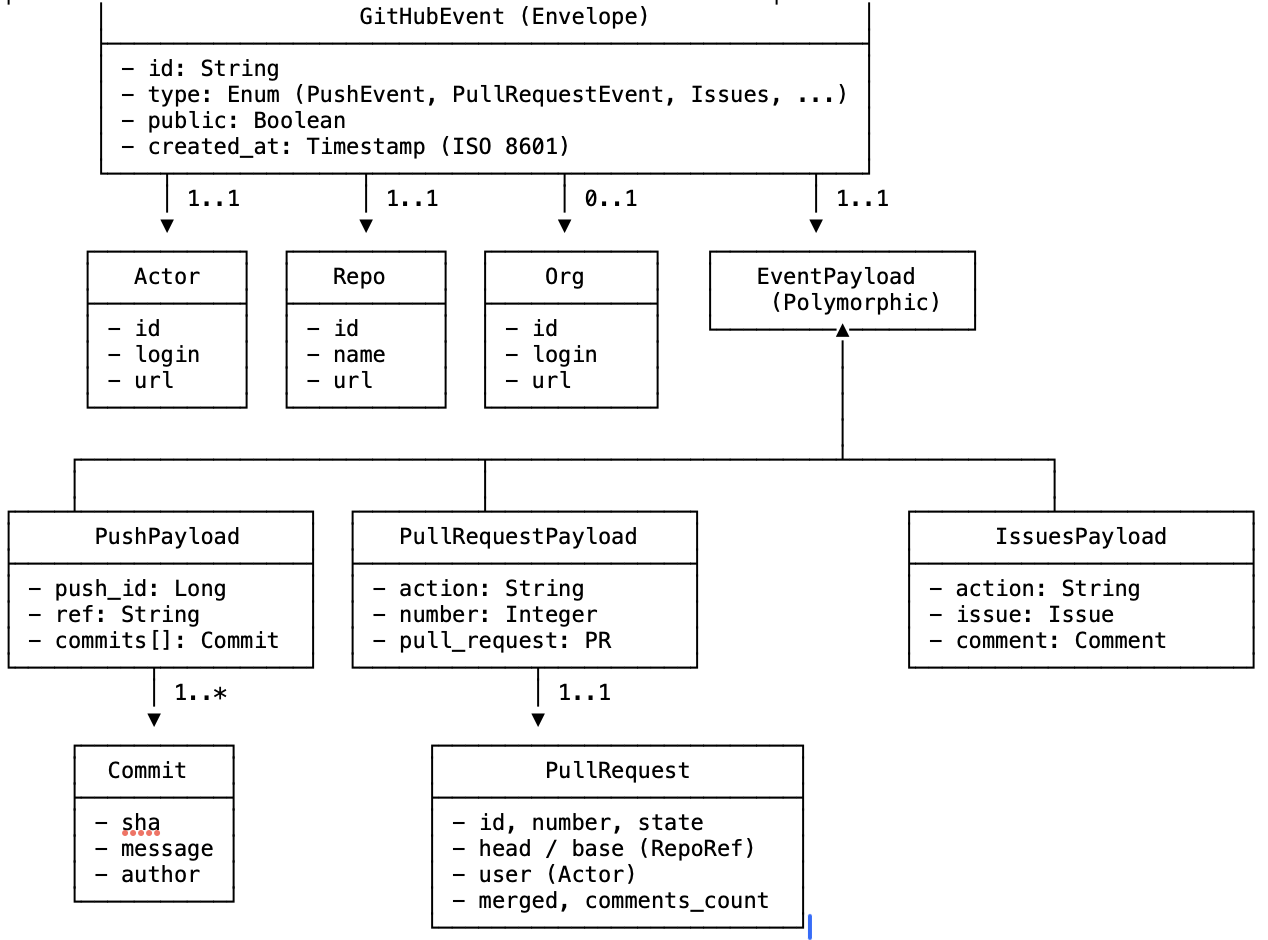